In [1]:
import os
import glob
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configurazione stile grafici
sns.set_theme(style="whitegrid")
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["figure.dpi"] = 150

In [2]:
EXP_BASE_DIR = "experiments/backbone_evaluation"

# Trova tutte le cartelle results_*
results_dirs = sorted(glob.glob(os.path.join(EXP_BASE_DIR, "results_20261012*")))

dfs = []
raw_feature_names = []

# Primo passaggio: raccoglie tutti i dati e i nomi univoci dei dataset
for r_dir in results_dirs:
    csv_path = os.path.join(r_dir, "results.csv")
    json_path = os.path.join(r_dir, "metadata.json")
    
    if os.path.exists(csv_path):
        df = pd.read_csv(csv_path)
        exp_id = os.path.basename(r_dir).replace("results_", "")
        
        feature_name = exp_id
        pooling = "N/A"
        if os.path.exists(json_path):
            with open(json_path, mode="r", encoding="utf-8") as f:
                meta = json.load(f)
                raw_name = meta.get("feature_name", exp_id)
                feature_name = raw_name.replace("train__", "").replace(".pt", "")
                pooling = meta.get("pooling", "N/A")
        
        df["experiment_id"] = exp_id
        df["feature_name"] = feature_name
        df["pooling"] = pooling
        dfs.append(df)
        
        if feature_name not in raw_feature_names:
            raw_feature_names.append(feature_name)

df_all = pd.concat(dfs, ignore_index=True)

# Crea la mappatura univoca: Feature Name -> Lettera (A, B, C, ...)
unique_features = sorted(df_all["feature_name"].unique())
letter_map = {name: chr(65 + i) for i, name in enumerate(unique_features)}

df_all["dataset_label"] = df_all["feature_name"].map(letter_map)
df_all["accuracy_mean"] = df_all["accuracy_mean"].astype(float)
df_all["macro_f1_mean"] = df_all["macro_f1_mean"].astype(float)

# Stampa Legenda Mappatura
print("=" * 80)
print("LEGENDA DATASET (MAPPATURA LETTERE -> NOMI COMPLETI)")
print("=" * 80)
for name, letter in letter_map.items():
    print(f"  Dataset [{letter}] ──► {name}")
print("=" * 80)

display(df_all[["dataset_label", "phase", "prober_name", "accuracy_mean", "macro_f1_mean", "pooling"]].head(12))

LEGENDA DATASET (MAPPATURA LETTERE -> NOMI COMPLETI)
  Dataset [A] ──► x3ds__trackernone__edgedense16s100__letterbox192__rgb__c7ed35d8
  Dataset [B] ──► x3ds__trackernone__edgedense16s100__stretch192__rgb__d2f97d0f
  Dataset [C] ──► x3ds__trackernone__edgedense32s100__stretch192__rgb__40670f36
  Dataset [D] ──► x3ds__trackernone__legacyuniform16__letterbox192__rgb__7fcd7c8f
  Dataset [E] ──► x3ds__trackernone__legacyuniform16__stretch192__rgb__b67ebd93
  Dataset [F] ──► x3ds__trackernone__legacyuniform32__stretch192__rgb__496ce8a3


,dataset_label,phase,prober_name,accuracy_mean,macro_f1_mean,pooling
0,A,p1,MLP_L1_H256,0.770000,0.732466,mean
1,A,p1,MLP_L2_H256,0.802222,0.779182,mean
2,A,p1,MLP_L3_H256,0.791852,0.764231,mean
3,A,p1,kNN_Probe_k3_cosine,0.733333,0.690121,mean
4,A,p2,MLP_L1_H256,0.680000,0.666028,mean
5,A,p2,MLP_L2_H256,0.686154,0.664570,mean
6,A,p2,MLP_L3_H256,0.636923,0.610021,mean
7,A,p2,kNN_Probe_k3_cosine,0.553846,0.461905,mean
8,A,p3,MLP_L1_H256,0.615385,0.603518,mean
9,A,p3,MLP_L2_H256,0.612308,0.610082,mean


In [10]:
# Vista pivot per confrontare le F1-Macro tra le lettere assegnate ai dataset
pivot_f1 = df_all.pivot_table(
    index=["phase", "prober_name"],
    columns="dataset_label",
    values="macro_f1_mean"
)

letter_cols = [c for c in pivot_f1.columns]
pivot_f1["Mean F1"] = pivot_f1[letter_cols].mean(axis=1)

# 1. Gradiente Globale su tutta la tabella (axis=None)
print("=== CONFRONTO MACRO F1-SCORE PER DATASET (GRADIENTE GLOBALE) ===")
display(
    pivot_f1.style.background_gradient(
        cmap="YlGn", 
        subset=letter_cols + ["Mean F1"], 
        axis=None  # Calcola min e max su tutte le celle selezionate insieme
    )
)

=== CONFRONTO MACRO F1-SCORE PER DATASET (GRADIENTE GLOBALE) ===


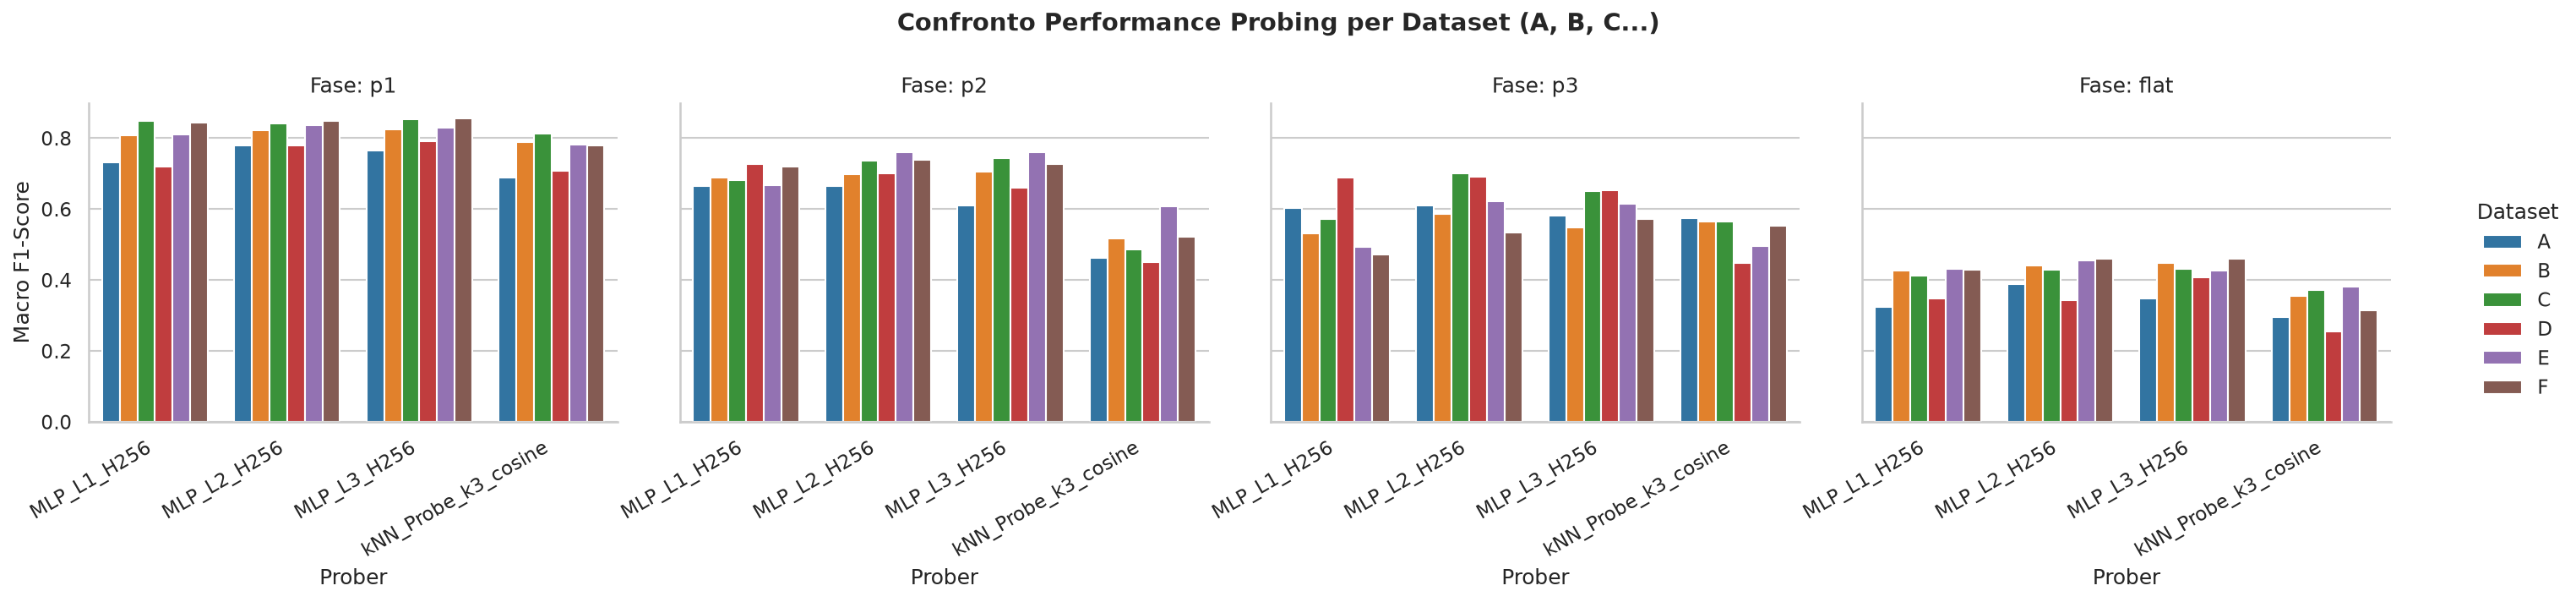

In [4]:
# Grafico a barre con legende e assi estremamente leggibili
g = sns.catplot(
    data=df_all,
    kind="bar",
    x="prober_name",
    y="macro_f1_mean",
    hue="dataset_label",
    col="phase",
    aspect=1.2,
    height=4,
    palette="tab10"
)

g.set_axis_labels("Prober", "Macro F1-Score")
g.set_titles("Fase: {col_name}")
g.set_xticklabels(rotation=30, ha="right")
g._legend.set_title("Dataset")
g.fig.subplots_adjust(top=0.8)
g.fig.suptitle("Confronto Performance Probing per Dataset (A, B, C...)", fontsize=14, fontweight="bold")

plt.show()

=== MIGLIOR PROBER PER DATASET E FASE ===


,dataset_label,feature_name,phase,prober_name,accuracy_mean,macro_f1_mean
0,F,x3ds__trackernone__legacyuniform32__stretch192...,flat,MLP_L3_H256,0.712593,0.461128
1,E,x3ds__trackernone__legacyuniform16__stretch192...,flat,MLP_L2_H256,0.705185,0.455146
2,B,x3ds__trackernone__edgedense16s100__stretch192...,flat,MLP_L3_H256,0.706667,0.447156
3,C,x3ds__trackernone__edgedense32s100__stretch192...,flat,MLP_L3_H256,0.741481,0.432273
4,D,x3ds__trackernone__legacyuniform16__letterbox1...,flat,MLP_L3_H256,0.702222,0.408586
5,A,x3ds__trackernone__edgedense16s100__letterbox1...,flat,MLP_L2_H256,0.663333,0.387510
6,F,x3ds__trackernone__legacyuniform32__stretch192...,p1,MLP_L3_H256,0.845556,0.855944
7,C,x3ds__trackernone__edgedense32s100__stretch192...,p1,MLP_L3_H256,0.834444,0.854536
8,E,x3ds__trackernone__legacyuniform16__stretch192...,p1,MLP_L2_H256,0.825926,0.837777
9,B,x3ds__trackernone__edgedense16s100__stretch192...,p1,MLP_L3_H256,0.812963,0.826020


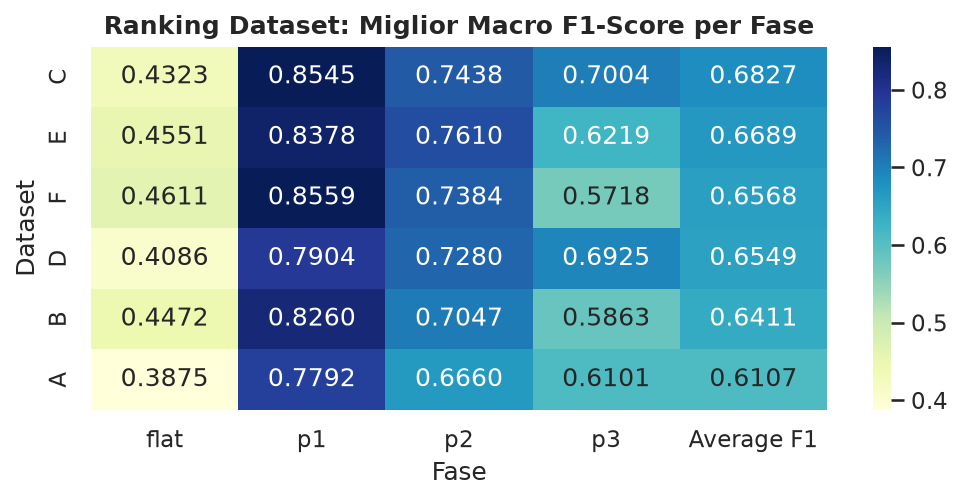

In [5]:
# Identifica il miglior prober per ogni fase e dataset
best_per_phase = df_all.loc[df_all.groupby(["dataset_label", "phase"])["macro_f1_mean"].idxmax()]

print("=== MIGLIOR PROBER PER DATASET E FASE ===")
display(
    best_per_phase[["dataset_label", "feature_name", "phase", "prober_name", "accuracy_mean", "macro_f1_mean"]]
    .sort_values(by=["phase", "macro_f1_mean"], ascending=[True, False])
    .reset_index(drop=True)
)

# Heatmap sintetica con le sole lettere sui diversi assi
best_pivot = best_per_phase.pivot(index="dataset_label", columns="phase", values="macro_f1_mean")
best_pivot["Average F1"] = best_pivot.mean(axis=1)
best_pivot = best_pivot.sort_values(by="Average F1", ascending=False)

plt.figure(figsize=(7, 3.5))
sns.heatmap(best_pivot, annot=True, fmt=".4f", cmap="YlGnBu", cbar=True)
plt.title("Ranking Dataset: Miglior Macro F1-Score per Fase", fontsize=12, fontweight="bold")
plt.ylabel("Dataset")
plt.xlabel("Fase")
plt.tight_layout()
plt.show()